<a href="https://colab.research.google.com/github/rahul18107/deep-learning/blob/main/SRahul_1BM24CD054_LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import models, layers

(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [6]:
PIXEL_MAX = 255.0

x_train = x_train.astype('float32') / PIXEL_MAX
x_test = x_test.astype('float32') / PIXEL_MAX

In [7]:
TIME_STEPS = 28
FEATURES = 28

x_train = x_train.reshape(-1, TIME_STEPS, FEATURES)
x_test = x_test.reshape(-1, TIME_STEPS, FEATURES)

In [8]:
NUM_CLASSES = 10

y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_test = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

In [10]:
RNN_UNITS = 128
OUT_UNITS = 10

model = models.Sequential()

model.add(layers.SimpleRNN(
    RNN_UNITS,
    activation='relu',
    input_shape=(TIME_STEPS, FEATURES)
))

In [12]:
model.add(layers.Dense(OUT_UNITS, activation=None))

In [14]:
# Q3a: Compile model
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Q3b: Train model
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(x_test, y_test)
)

# Evaluate model
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.9742 - loss: 0.0864 - val_accuracy: 0.9697 - val_loss: 0.1066
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9761 - loss: 0.0817 - val_accuracy: 0.9735 - val_loss: 0.0982
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9767 - loss: 0.0783 - val_accuracy: 0.9677 - val_loss: 0.1096
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9774 - loss: 0.0765 - val_accuracy: 0.9727 - val_loss: 0.1013
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9781 - loss: 0.0753 - val_accuracy: 0.9746 - val_loss: 0.0909
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9794 - loss: 0.0696 - val_accuracy: 0.9761 - val_loss: 0.0889
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9800 - loss: 0.0673 - val_accuracy: 0.9763 - val_loss: 0.0912
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9815 - loss: 0.0639 - val_accuracy: 0

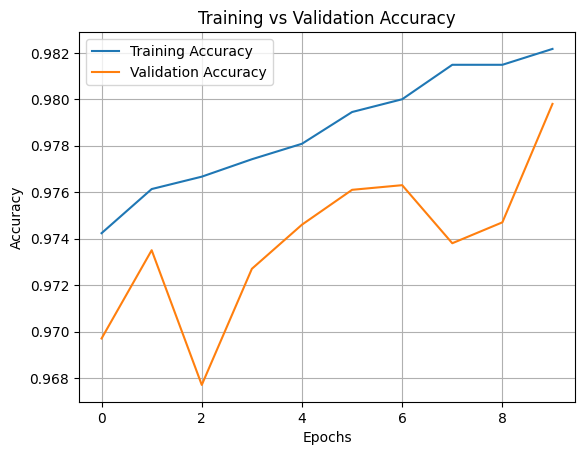

In [15]:

import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()
